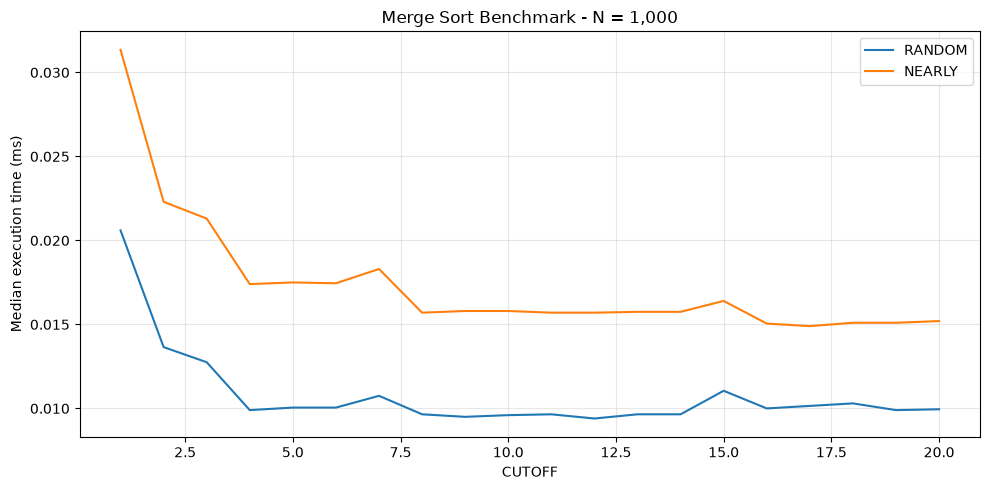

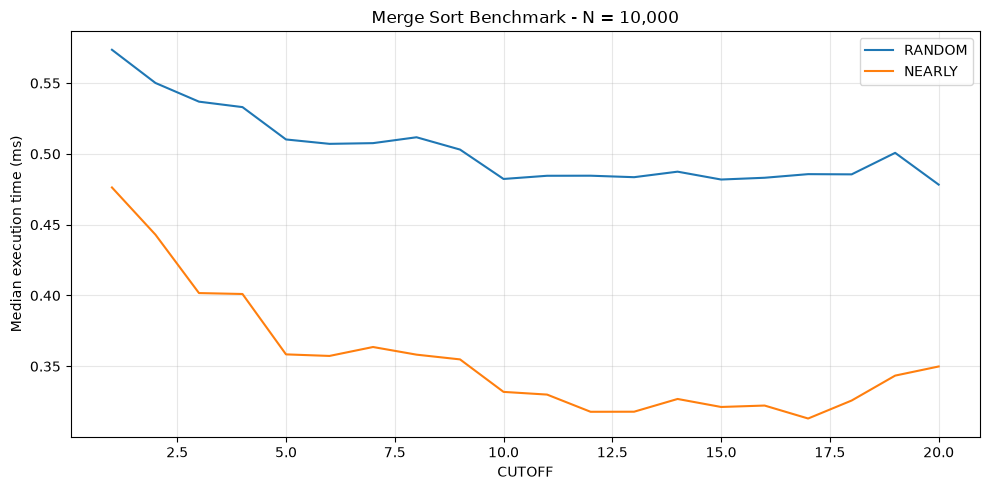

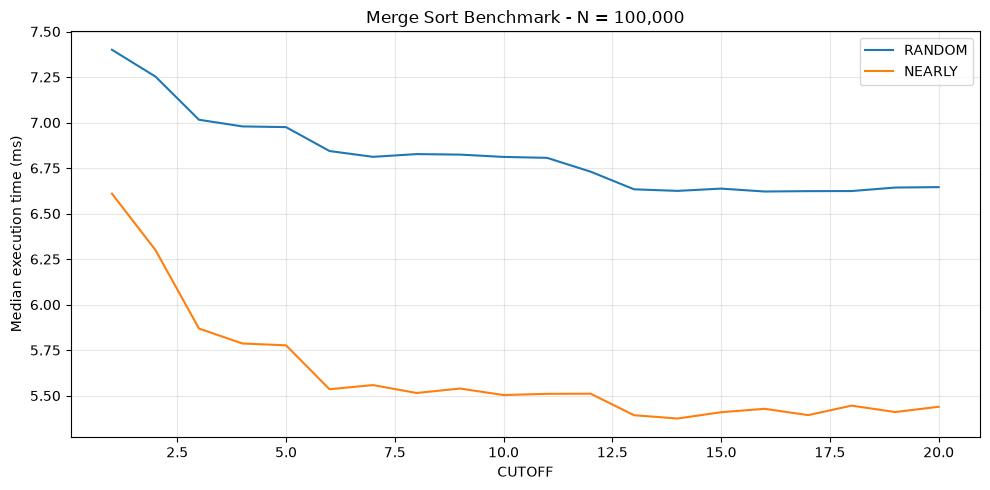

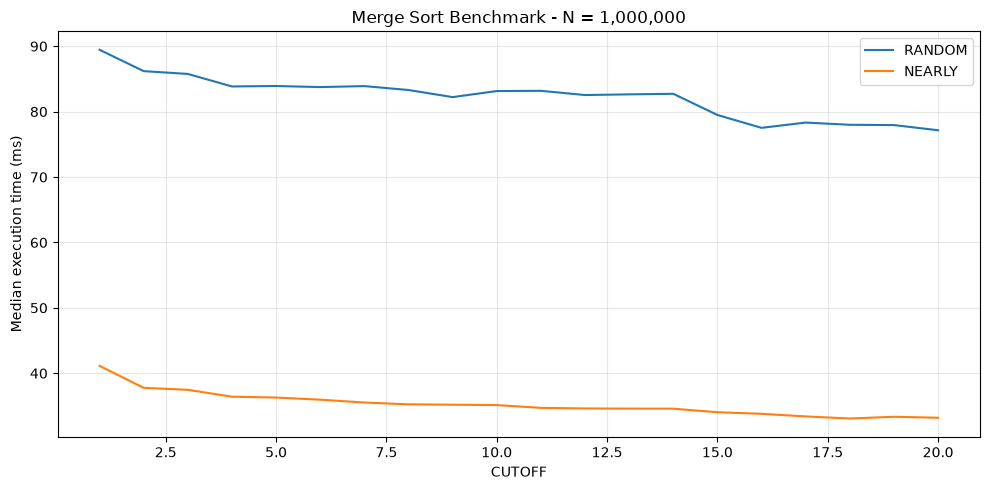

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("result.csv")

df["time_ms"] = df["time_ns"] / 1_000_000

summary = (
    df.groupby(["size", "id_type", "cutoff"])["time_ms"]
      .median()
      .reset_index()
)

names = {
    1: "RANDOM",
    2: "NEARLY",
    3: "REVERSED",
    4: "SORTED"
}

for size in sorted(summary["size"].unique()):
    subset = summary[summary["size"] == size]

    plt.figure(figsize=(10, 5))

    for type_id, group in subset.groupby("id_type"):
        plt.plot(
            group["cutoff"],
            group["time_ms"],
            label=names[type_id]
        )

    plt.xlabel("CUTOFF")
    plt.ylabel("Median execution time (ms)")
    plt.title(f"Merge Sort Benchmark - N = {size:,}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()